In [2]:
import pandas as pd
import numpy as np
# from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path

In [3]:
RESULTS_DIR = Path("../results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")
motif_file = RESULTS_DIR / "atob_mtft_e005_f010.csv"
faithfulness_file = RESULTS_DIR / "atobff005010100.csv"

In [4]:
fwords_df = pd.read_csv("../data/function_words_277.csv")
fwords = fwords_df["word"].tolist()

In [5]:
def motif_to_fwords(motif, function_words):
    """
    Convert motifs to function words.
    """
    if isinstance(motif, str):
        motif = ast.literal_eval(motif)

    return " ".join(
        f"({function_words[u]}, {function_words[v]})"
        for u, v in motif
    )

### 1. Analyze motifs across human and machine graphs


In [6]:
motifs_df = pd.read_csv(motif_file)
motifs_df

,row,label,motif,feature,importance,graph_feature_importance
0,13,0,"((49, 28), (49, 66))",50,0.513952,0.434023
1,13,0,"((49, 28), (49, 66))",55,0.474959,0.459632
2,13,0,"((49, 28), (49, 66))",57,0.460918,0.469667
3,13,0,"((49, 28), (49, 66))",60,0.506981,0.455892
4,13,0,"((49, 28), (49, 66))",63,0.479100,0.467424
...,...,...,...,...,...,...
48439,2399,1,"((2, 92), (25, 2))",66,0.195110,0.191697
48440,2399,1,"((2, 92), (25, 2))",73,0.177004,0.167454
48441,2399,1,"((2, 92), (25, 2))",80,0.316844,0.216617
48442,2399,1,"((2, 92), (25, 2))",86,0.233522,0.188519


### A1 Which motif-feature combinations have particularly high importance compared with their graph-wide baseline?

In [9]:
df = motifs_df.copy()

df["feature_difference"] = (
    df["importance"] - df["graph_feature_importance"]
)

df["class"] = df["label"].map({
    0: "Human",
    1: "Machine"
})

display(df)

,row,label,motif,feature,importance,graph_feature_importance,feature_difference,class
0,13,0,"((49, 28), (49, 66))",50,0.513952,0.434023,0.079929,Human
1,13,0,"((49, 28), (49, 66))",55,0.474959,0.459632,0.015327,Human
2,13,0,"((49, 28), (49, 66))",57,0.460918,0.469667,-0.008749,Human
3,13,0,"((49, 28), (49, 66))",60,0.506981,0.455892,0.051088,Human
4,13,0,"((49, 28), (49, 66))",63,0.479100,0.467424,0.011676,Human
...,...,...,...,...,...,...,...,...
48439,2399,1,"((2, 92), (25, 2))",66,0.195110,0.191697,0.003413,Machine
48440,2399,1,"((2, 92), (25, 2))",73,0.177004,0.167454,0.009550,Machine
48441,2399,1,"((2, 92), (25, 2))",80,0.316844,0.216617,0.100226,Machine
48442,2399,1,"((2, 92), (25, 2))",86,0.233522,0.188519,0.045003,Machine


In [8]:
graph_summary = (
    df.groupby(["row", "label", "class"])
    .agg(
        mean_motif_importance=("importance", "mean"),
        mean_graph_importance=("graph_feature_importance", "mean"),
        mean_difference=("feature_difference", "mean"),
        n_motifs=("motif", "nunique"),
        n_features=("feature", "nunique")
    )
    .reset_index()
)

display(graph_summary.head())

,row,label,class,mean_motif_importance,mean_graph_importance,mean_difference,n_motifs,n_features
0,13,0,Human,0.477491,0.455465,0.022026,9,11
1,17,0,Human,0.365815,0.323318,0.042497,16,11
2,20,0,Human,0.294179,0.247115,0.047064,18,11
3,22,0,Human,0.400920,0.342305,0.058614,9,11
4,28,0,Human,0.164443,0.155008,0.009435,16,11


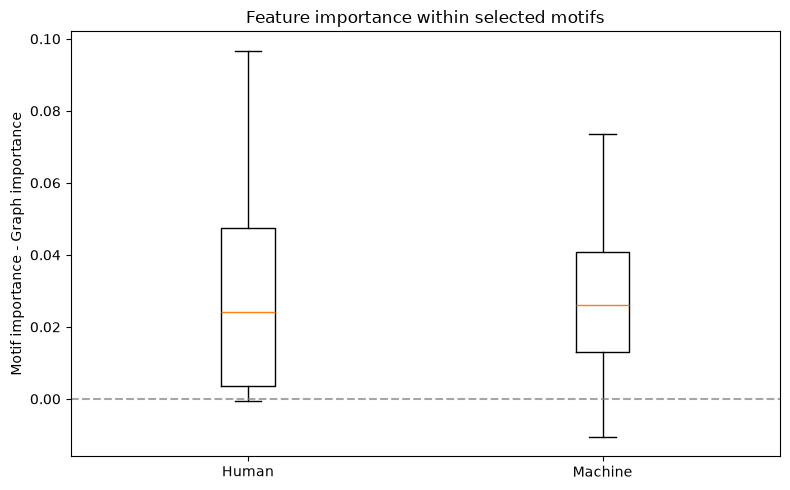

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

human = graph_summary.loc[
    graph_summary["label"] == 0,
    "mean_difference"
]

machine = graph_summary.loc[
    graph_summary["label"] == 1,
    "mean_difference"
]

ax.boxplot(
    [human, machine],
    showfliers=False
)

ax.set_xticks([1, 2])
ax.set_xticklabels(["Human", "Machine"])

ax.axhline(0, color="gray", linestyle="--", alpha=0.7)

ax.set_ylabel("Motif importance - Graph importance")
ax.set_title("Feature importance within selected motifs")

plt.tight_layout()
plt.show()

Conclusion:
* Selected features in general do not receive larger importance increase within selected motifs.

### A2 Do human and machine motifs emphasize different features?

In [13]:
df = motifs_df.copy()

df["feature_difference"] = (
    df["importance"]
    - df["graph_feature_importance"]
)

graph_feature_df = (
    df.groupby(["row", "label", "feature"])
    .agg(
        mean_motif_importance=("importance", "mean"),
        graph_feature_importance=("graph_feature_importance", "first"),
        mean_difference=("feature_difference", "mean"),
        n_motifs=("motif", "nunique")
    )
    .reset_index()
)

In [14]:
graph_feature_df

,row,label,feature,mean_motif_importance,graph_feature_importance,mean_difference,n_motifs
0,13,0,50,0.469027,0.434023,0.035003,9
1,13,0,55,0.468367,0.459632,0.008735,9
2,13,0,57,0.477827,0.469667,0.008159,9
3,13,0,60,0.516061,0.455892,0.060169,9
4,13,0,63,0.465636,0.467424,-0.001788,9
...,...,...,...,...,...,...,...
3823,2399,1,66,0.224212,0.191697,0.032515,3
3824,2399,1,73,0.189144,0.167454,0.021690,3
3825,2399,1,80,0.245792,0.216617,0.029174,3
3826,2399,1,86,0.222909,0.188519,0.034390,3


In [16]:
feature_summary = (
    graph_feature_df
    .groupby(["feature", "label"])
    .agg(
        mean_difference=("mean_difference", "mean"),
        mean_importance=("mean_motif_importance", "mean"),
        n_graphs=("row", "nunique")
    )
    .reset_index()
)

feature_comparison = feature_summary.pivot(
    index="feature",
    columns="label",
    values=["mean_difference", "mean_importance", "n_graphs"]
)

feature_comparison.columns = [
    f"{metric}_{'human' if label == 0 else 'machine'}"
    for metric, label in feature_comparison.columns
]

feature_comparison = feature_comparison.reset_index()

feature_comparison["difference"] = (
    feature_comparison["mean_difference_machine"]
    - feature_comparison["mean_difference_human"]
)

In [19]:
feature_comparison

,feature,label,mean_importance,mean_difference,n_graphs
0,0,0,0.395827,0.222721,9
1,2,0,0.145358,0.000659,4
2,3,0,0.142490,-0.002048,2
3,4,0,0.145485,0.000567,20
4,6,0,0.146336,0.002311,3
...,...,...,...,...,...
105,97,0,0.145458,0.001172,4
106,98,0,0.145502,0.000696,5
107,99,0,0.141260,-0.002592,1
108,100,1,0.240711,0.022105,169


In [22]:
min_graphs = 5

feature_comparison = feature_comparison[
    (feature_comparison["n_graphs_human"] >= min_graphs)
    & (feature_comparison["n_graphs_machine"] >= min_graphs)
].copy()

feature_comparison["abs_difference"] = (
    feature_comparison["difference"].abs()
)

feature_comparison = feature_comparison.sort_values(
    "abs_difference",
    ascending=False
)

display(feature_comparison.head(20))

,feature,mean_difference_human,mean_difference_machine,mean_importance_human,mean_importance_machine,n_graphs_human,n_graphs_machine,difference,abs_difference
52,57,0.028123,0.097684,0.366957,0.547430,145.0,169.0,0.069560,0.069560
55,60,0.052282,0.005063,0.330081,0.209933,154.0,163.0,-0.047219,0.047219
80,86,0.061745,0.019604,0.350603,0.233684,166.0,169.0,-0.042141,0.042141
58,63,0.000553,-0.035956,0.310512,0.309410,145.0,169.0,-0.036509,0.036509
50,55,0.040486,0.074168,0.357377,0.382488,142.0,169.0,0.033682,0.033682
74,80,0.030471,0.013397,0.309074,0.260577,117.0,169.0,-0.017075,0.017075
39,42,0.044158,0.034195,0.319580,0.258298,78.0,169.0,-0.009962,0.009962
61,66,0.043883,0.052850,0.320641,0.282168,129.0,148.0,0.008967,0.008967
63,68,-0.000298,-0.009125,0.289768,0.283902,157.0,33.0,-0.008827,0.008827
89,96,0.046132,0.038290,0.318584,0.277725,160.0,17.0,-0.007841,0.007841


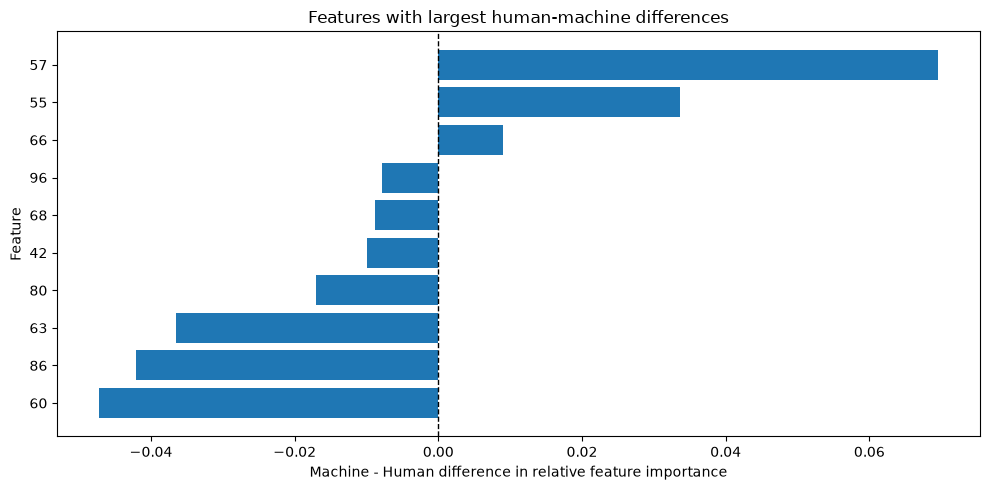

In [23]:
top_n = 20

plot_df = feature_comparison.head(top_n).copy()
plot_df = plot_df.sort_values("difference")

fig, ax = plt.subplots(
    figsize=(10, max(5, len(plot_df) * 0.35))
)

ax.barh(
    plot_df["feature"].astype(str),
    plot_df["difference"]
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Machine - Human difference in relative feature importance"
)

ax.set_ylabel("Feature")
ax.set_title("Features with largest human-machine differences")

plt.tight_layout()
plt.show()

### Faithfulness

In [24]:
df = pd.read_csv(faithfulness_file)

summary = (
    df.groupby("class")
    .agg(
        n_graphs=("row", "count"),
        sufficiency=("sufficiency", "mean"),
        sufficiency_random=("sufficiency_random", "mean"),
        comprehensiveness=("comprehensiveness", "mean"),
        comprehensiveness_random=("comprehensiveness_random", "mean")
    )
)

display(summary.round(4))

,n_graphs,sufficiency,sufficiency_random,comprehensiveness,comprehensiveness_random
class,,,,,
Human,180,0.7858,0.2032,0.1270,0.2054
Machine,178,-0.0051,0.7845,0.9949,0.3105


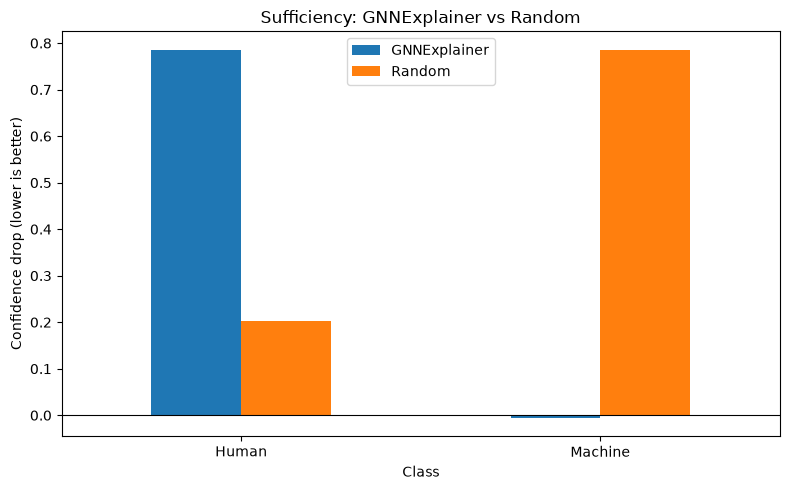

In [27]:
plot_df = summary[
    ["sufficiency", "sufficiency_random"]
].rename(columns={
    "sufficiency": "GNNExplainer",
    "sufficiency_random": "Random"
})

ax = plot_df.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Sufficiency: GNNExplainer vs Random")
ax.set_ylabel("Confidence drop (lower is better)")
ax.set_xlabel("Class")

ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

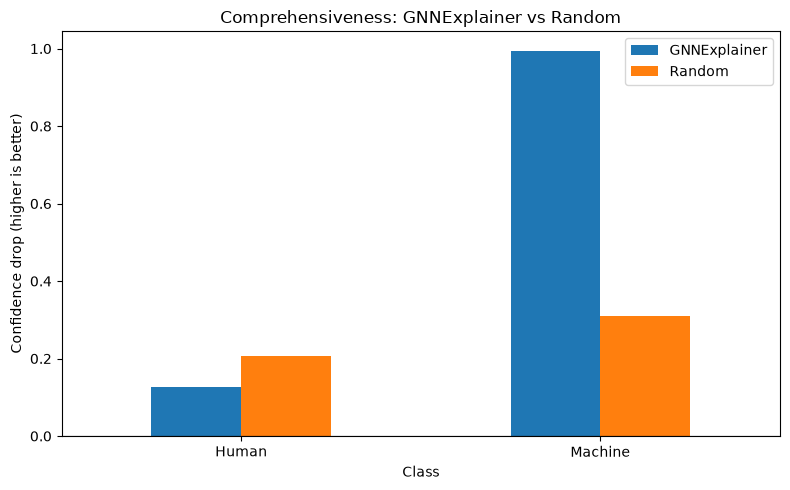

In [29]:
plot_df = summary[
    ["comprehensiveness", "comprehensiveness_random"]
].rename(columns={
    "comprehensiveness": "GNNExplainer",
    "comprehensiveness_random": "Random"
})

ax = plot_df.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Comprehensiveness: GNNExplainer vs Random")
ax.set_ylabel("Confidence drop (higher is better)")
ax.set_xlabel("Class")

ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

In [30]:
df["sufficiency_gain"] = (
    df["sufficiency_random"]
    - df["sufficiency"]
)

df["comprehensiveness_gain"] = (
    df["comprehensiveness"]
    - df["comprehensiveness_random"]
)

display(
    df.groupby("class")[
        ["sufficiency_gain", "comprehensiveness_gain"]
    ].agg(["mean", "median", "std"])
)

sufficiency_gain                     comprehensiveness_gain           \
                    mean    median       std                   mean   median   
class                                                                          
Human          -0.582599 -0.778574  0.405205              -0.078446 -0.18876   
Machine         0.789588  0.789986  0.038919               0.684358  0.69311   

                   
              std  
class              
Human    0.343259  
Machine  0.077777

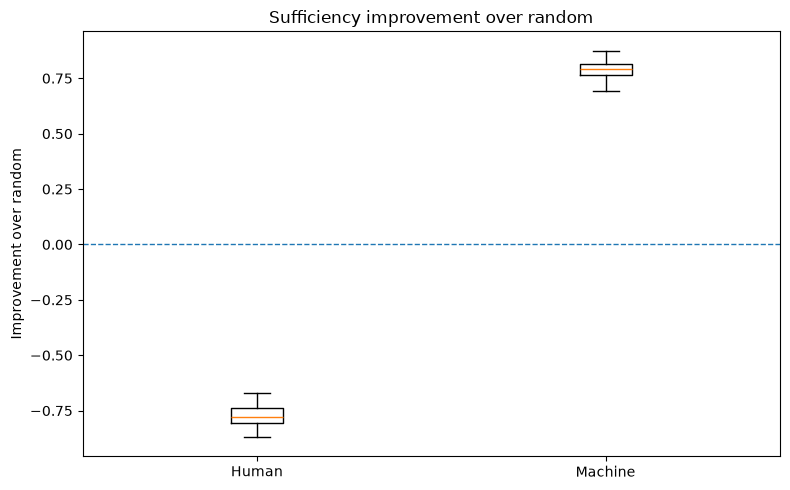

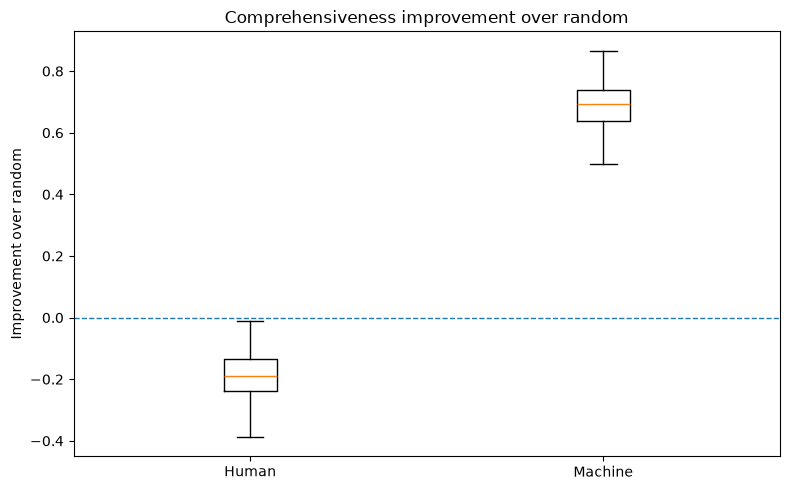

In [31]:
for metric, title in [
    ("sufficiency_gain", "Sufficiency improvement over random"),
    ("comprehensiveness_gain", "Comprehensiveness improvement over random")
]:

    human = df.loc[
        df["class"] == "Human", metric
    ].dropna()

    machine = df.loc[
        df["class"] == "Machine", metric
    ].dropna()

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.boxplot(
        [human, machine],
        showfliers=False
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Human", "Machine"])

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_ylabel("Improvement over random")
    ax.set_title(title)

    plt.tight_layout()
    plt.show()

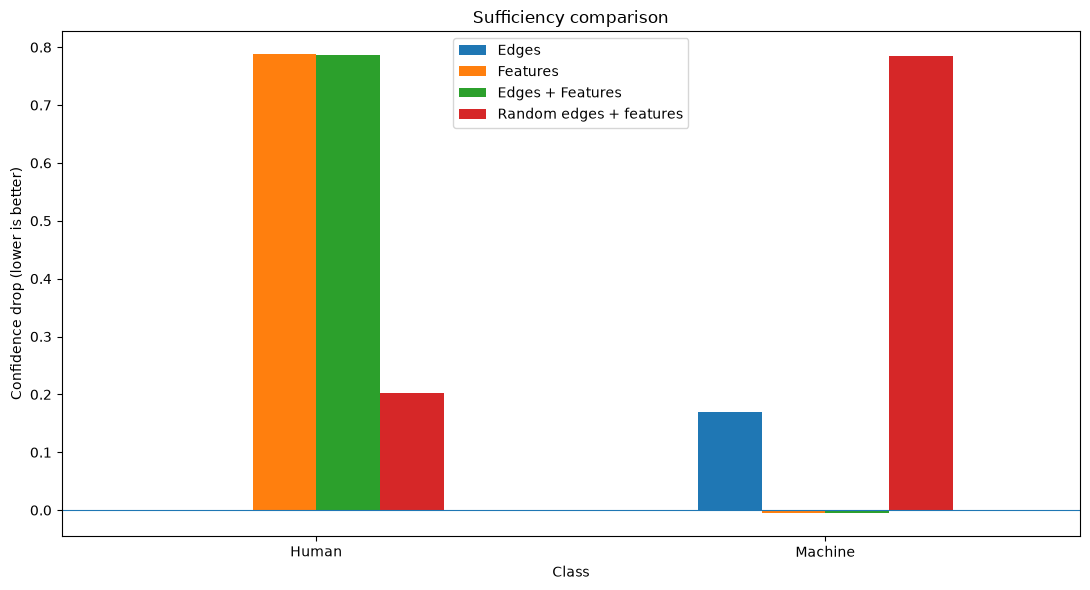

In [32]:
sufficiency_cols = {
    "sufficiency_edge": "Edges",
    "sufficiency_feature": "Features",
    "sufficiency": "Edges + Features",
    "sufficiency_random": "Random edges + features"
}

suff_summary = (
    df.groupby("class")[list(sufficiency_cols)]
    .mean()
    .rename(columns=sufficiency_cols)
)

ax = suff_summary.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title("Sufficiency comparison")
ax.set_ylabel("Confidence drop (lower is better)")
ax.set_xlabel("Class")

ax.axhline(0, linewidth=0.8)

plt.tight_layout()
plt.show()

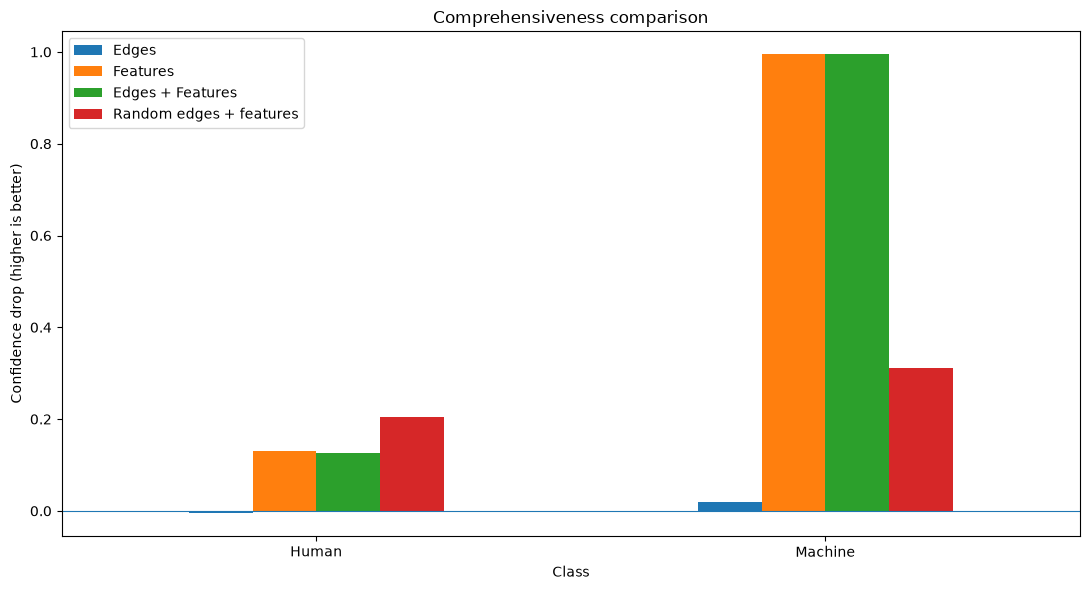

In [34]:
comp_cols = {
    "comprehensiveness_edge": "Edges",
    "comprehensiveness_feature": "Features",
    "comprehensiveness": "Edges + Features",
    "comprehensiveness_random": "Random edges + features"
}

comp_summary = (
    df.groupby("class")[list(comp_cols)]
    .mean()
    .rename(columns=comp_cols)
)

ax = comp_summary.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title("Comprehensiveness comparison")
ax.set_ylabel("Confidence drop (higher is better)")
ax.set_xlabel("Class")

ax.axhline(0, linewidth=0.8)

plt.tight_layout()
plt.show()